# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [62]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [63]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [64]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [65]:
numbers = list(range(10))  # список для shuffle

print("--> До set_seed() <--")
nums1 = numbers.copy()
random.shuffle(nums1)
print("Спроба 1:", random.randint(1, 100), nums1)

nums2 = numbers.copy()
random.shuffle(nums2)
print("Спроба 2:", random.randint(1, 100), nums2)

set_seed()
print("Seed зафіксовано:", SEED)

print("\n--> Після set_seed() (із скиданням перед кожним запуском) <--")
set_seed()
nums3 = numbers.copy()
random.shuffle(nums3)
print("Спроба 1:", random.randint(1, 100), nums3)

set_seed()
nums4 = numbers.copy()
random.shuffle(nums4)
print("Спроба 2:", random.randint(1, 100), nums4)

print("\n--> Двічі без проміжних викликів set_seed() <--")
nums5 = numbers.copy()
random.shuffle(nums5)
print("Спроба 1:", random.randint(1, 100), nums5)

nums6 = numbers.copy()
random.shuffle(nums6)
print("Спроба 2:", random.randint(1, 100), nums6)


--> До set_seed() <--
Спроба 1: 5 [7, 5, 2, 8, 9, 6, 1, 3, 4, 0]
Спроба 2: 92 [6, 7, 2, 9, 5, 4, 8, 3, 1, 0]
Seed зафіксовано: 42

--> Після set_seed() (із скиданням перед кожним запуском) <--
Спроба 1: 76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2: 76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

--> Двічі без проміжних викликів set_seed() <--
Спроба 1: 92 [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
Спроба 2: 44 [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


1. **До виклику `set_seed()`**: Генератор псевдовипадкових чисел перебуває у довільному початковому стані (зазвичай ініціалізується системним часом), тому кожна операція (`randint`, `shuffle`) дає унікальні, непередбачувані результати.
2. **Виклик `set_seed()` перед кожною генерацією**: Скидає стан генератора до одного й того самого фіксованого значення (`SEED = 42`). У результаті послідовність внутрішніх операцій повторюється абсолютно ідентично — обидві спроби генерують однакове число та однакове перемішування списку.
3. **Генерація без проміжного виклику `set_seed()`**: Після одноразової ініціалізації генератор продовжує видавати наступні значення у своїй фіксованій псевдовипадковій послідовності. Між собою ці спроби відрізняються, проте при повторному перезапуску всього блокнота ця пара значень завжди буде однаковою (детермінованою).

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [66]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [67]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [68]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [69]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [70]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Identity matrix:\n", identity)
print("ndim identity:", identity.ndim)

print("\nRandom ints:\n", random_ints)
print("ndim random_ints:", random_ints.ndim)


Identity matrix:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
ndim identity: 2

Random ints:
 [[6 3 7]
 [4 6 9]
 [2 6 7]]
ndim random_ints: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [71]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [72]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [73]:
df = pd.DataFrame({
    "name": ["Олександр", "Дарина", "Іван", "Наталія", "Антон", "Артем"],
    "score": [95, 78, 88, 67, 92, 80]
})

top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)


        name  score
0  Олександр     95
4      Антон     92
2       Іван     88


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [74]:
def assign_grade(score):
    if score >= 90:
        return "A"
    elif score >= 75:
        return "B"
    else:
        return "C"

df["grade"] = df["score"].apply(assign_grade)
print(df)


        name  score grade
0  Олександр     95     A
1     Дарина     78     B
2       Іван     88     B
3    Наталія     67     C
4      Антон     92     A
5      Артем     80     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [75]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [76]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [77]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print("from_list:")
print(from_list)
print("shape:", from_list.shape, "| dtype:", from_list.dtype, "| ndim:", from_list.ndim)

print("\nrandom_t:")
print(random_t)
print("shape:", random_t.shape, "| dtype:", random_t.dtype, "| ndim:", random_t.ndim)


from_list:
tensor([[1, 2],
        [3, 4]])
shape: torch.Size([2, 2]) | dtype: torch.int64 | ndim: 2

random_t:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
shape: torch.Size([3, 3]) | dtype: torch.float32 | ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [78]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
grad_autograd = x.grad.item()
grad_analytic = 2 * n

print(f"Градієнт PyTorch (autograd): {grad_autograd}")
print(f"Аналітичний градієнт (2 * n): {grad_analytic}")
print(f"Градієнти співпадають: {grad_autograd == grad_analytic}")


Градієнт PyTorch (autograd): 10.0
Аналітичний градієнт (2 * n): 10.0
Градієнти співпадають: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [79]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
        x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

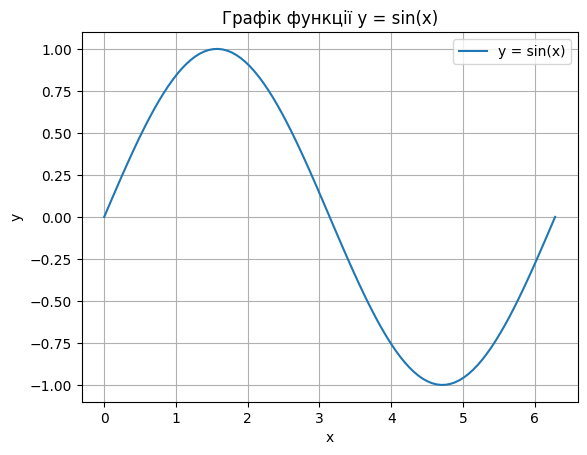

In [80]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs), label="y = sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Графік функції y = sin(x)")
plt.grid(True)
plt.legend()
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

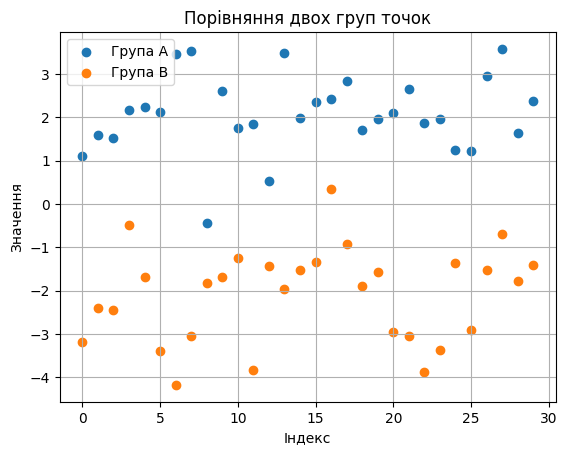

In [81]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(len(group_a)), group_a, color="C0", label="Група A")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Група B")

plt.xlabel("Індекс")
plt.ylabel("Значення")
plt.title("Порівняння двох груп точок")
plt.legend()
plt.grid(True)
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [82]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

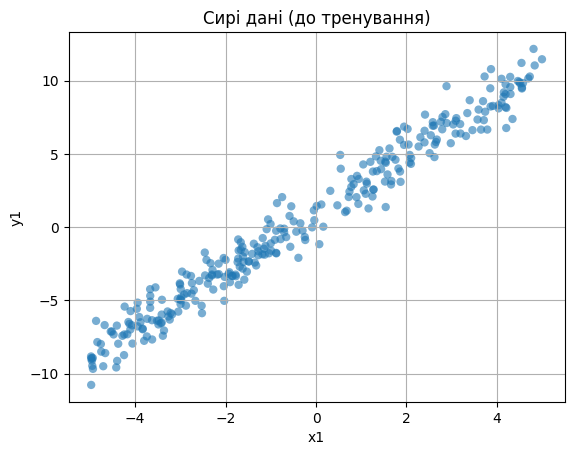

In [83]:
plt.scatter(x1.numpy(), y1.numpy(), alpha=0.6, edgecolors="none")
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(True)
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [84]:
n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)

indices = torch.randperm(TASK1_N)
x_shuffled = x1[indices]
y_shuffled = y1[indices]

x_train1, y_train1 = x_shuffled[:n_train], y_shuffled[:n_train]
x_val1, y_val1 = x_shuffled[n_train:n_train + n_val], y_shuffled[n_train:n_train + n_val]
x_test1, y_test1 = x_shuffled[n_train + n_val:], y_shuffled[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [85]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


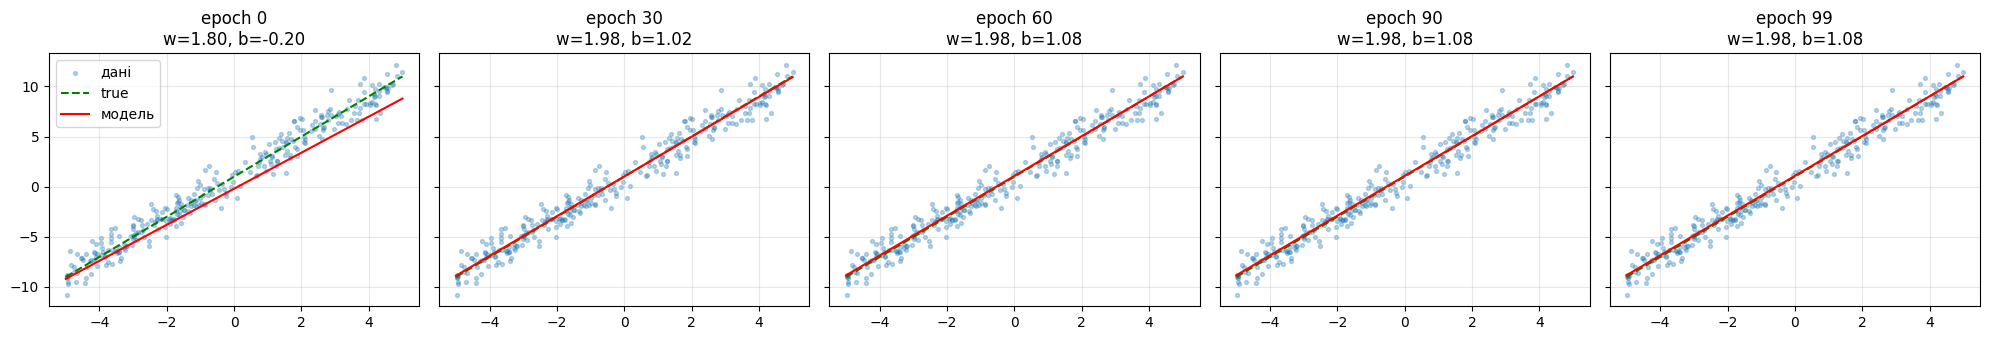

In [86]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: Залежність балу за іспит від часу підготовки

* **Вхідна ознака ($x$)**: кількість годин, витрачених на підготовку до іспиту (від 0 до 12 годин).
* **Цільова змінна ($y$)**: підсумковий бал за іспит (за шкалою від ~35 до 100 балів).
* **Закладені параметри**:
  * **$b = 40.0$ (bias)**: базовий бал, який можна набрати на залишках знань з лекцій чи інтуїції, навіть якщо зовсім не готуватися ($x = 0$).
  * **$w = 4.5$ (weight)**: кожна година сумлінної підготовки додає в середньому приблизно 4.5 бали до результату.
  * **$\varepsilon \sim \mathcal{N}(0, 3.0)$ (шум)**: випадкові фактори (складність конкретного білета, самопочуття на іспиті, удача).

Рівняння залежності: $y = 4.5 \cdot x + 40.0 + \varepsilon$.

Файл 'dataset.csv' збережено. Перші 5 рядків:
   study_hours  exam_score
0    10.587231   85.970978
1    10.980047   86.505173
2     4.594365   63.288483
3    11.511667   91.515579
4     4.685379   62.295616
Епоха 100 | Train Loss: 148.59 | Val Loss: 170.67 | w: 7.39 (істинне 4.5) | b: 17.41 (істинне 40.0)
Епоха 200 | Train Loss: 54.91 | Val Loss: 67.08 | w: 6.20 (істинне 4.5) | b: 26.86 (істинне 40.0)
Епоха 300 | Train Loss: 23.58 | Val Loss: 31.02 | w: 5.50 (істинне 4.5) | b: 32.32 (істинне 40.0)
Епоха 400 | Train Loss: 13.10 | Val Loss: 18.14 | w: 5.10 (істинне 4.5) | b: 35.48 (істинне 40.0)
Епоха 500 | Train Loss: 9.60 | Val Loss: 13.37 | w: 4.87 (істинне 4.5) | b: 37.31 (істинне 40.0)
Епоха 600 | Train Loss: 8.43 | Val Loss: 11.50 | w: 4.74 (істинне 4.5) | b: 38.36 (істинне 40.0)
Епоха 700 | Train Loss: 8.03 | Val Loss: 10.71 | w: 4.66 (істинне 4.5) | b: 38.97 (істинне 40.0)

--> Оцінка на тестовій вибірці <--
MSE помилка : 11.52
Середня похибка (MAE): 2.61 балів

Ваги моделі збер

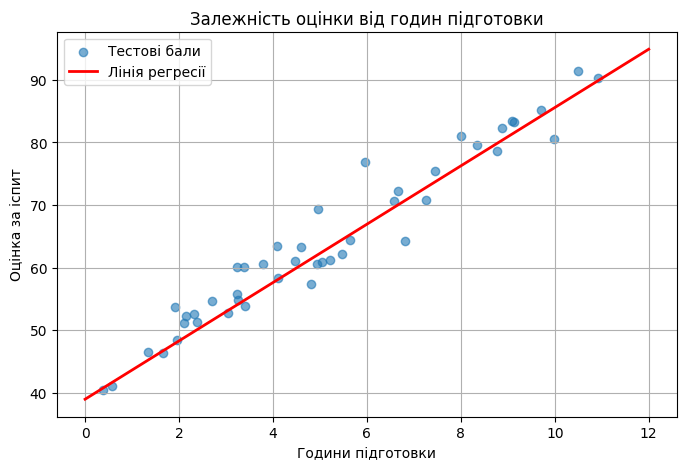

In [87]:
set_seed(SEED)

TRUE_W = 4.5
TRUE_B = 40.0
N_SAMPLES = 300

hours = torch.empty(N_SAMPLES, 1).uniform_(0.0, 12.0)
noise = torch.randn(N_SAMPLES, 1) * 3.0
scores = TRUE_W * hours + TRUE_B + noise
scores = torch.clamp(scores, min=0.0, max=100.0)

df_exam = pd.DataFrame({
    "study_hours": hours.squeeze().numpy(),
    "exam_score": scores.squeeze().numpy()
})
df_exam.to_csv("/content/drive/MyDrive/ai_systems/lab1/dataset.csv", index=False)
print("Файл 'dataset.csv' збережено. Перші 5 рядків:")
print(df_exam.head())

def split_data(x, y):
    n = len(x)
    indices = torch.randperm(n)
    x_sh = x[indices]
    y_sh = y[indices]

    n_train = int(0.70 * n)
    n_val = int(0.15 * n)

    return (
        (x_sh[:n_train], y_sh[:n_train]),
        (x_sh[n_train:n_train + n_val], y_sh[n_train:n_train + n_val]),
        (x_sh[n_train + n_val:], y_sh[n_train + n_val:])
    )

def train_model(model, x_train, y_train, x_val, y_val, lr=0.01, epochs=700):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        preds = model(x_train)
        loss = loss_fn(preds, y_train)
        loss.backward()
        optimizer.step()

        if epoch % 100 == 0 or epoch == epochs:
            model.eval()
            with torch.no_grad():
                val_loss = loss_fn(model(x_val), y_val)
            print(f"Епоха {epoch:3d} | Train Loss: {loss.item():.2f} | Val Loss: {val_loss.item():.2f} | "
                  f"w: {model.weight.item():.2f} (істинне {TRUE_W}) | b: {model.bias.item():.2f} (істинне {TRUE_B})")

def evaluate_model(model, x_test, y_test):
    model.eval()
    loss_fn = torch.nn.MSELoss()
    with torch.no_grad():
        test_preds = model(x_test)
        mse = loss_fn(test_preds, y_test).item()
        mae = torch.mean(torch.abs(test_preds - y_test)).item()
    print("\n--> Оцінка на тестовій вибірці <--")
    print(f"MSE помилка : {mse:.2f}")
    print(f"Середня похибка (MAE): {mae:.2f} балів")

(x_train, y_train), (x_val, y_val), (x_test, y_test) = split_data(hours, scores)

model = torch.nn.Linear(1, 1)
train_model(model, x_train, y_train, x_val, y_val, lr=0.01, epochs=700)
evaluate_model(model, x_test, y_test)

torch.save(model.state_dict(), "/content/drive/MyDrive/ai_systems/lab1/model.pt")
print("\nВаги моделі збережено у 'model.pt'")

plt.figure(figsize=(8, 5))
plt.scatter(x_test.numpy(), y_test.numpy(), color="C0", alpha=0.6, label="Тестові бали")
x_line = torch.linspace(0, 12, 100).unsqueeze(1)
with torch.no_grad():
    y_line = model(x_line)
plt.plot(x_line.numpy(), y_line.numpy(), color="red", linewidth=2, label="Лінія регресії")
plt.xlabel("Години підготовки")
plt.ylabel("Оцінка за іспит")
plt.title("Залежність оцінки від годин підготовки")
plt.legend()
plt.grid(True)
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [88]:
!pip install -q gradio
import gradio as gr
import torch

loaded_model = torch.nn.Linear(1, 1)
model_path = "/content/drive/MyDrive/ai_systems/lab1/model.pt"

try:
    loaded_model.load_state_dict(torch.load(model_path))
except FileNotFoundError:
    loaded_model.load_state_dict(torch.load("model.pt"))

loaded_model.eval()

def predict_score(study_hours):
    with torch.no_grad():
        x_input = torch.tensor([[float(study_hours)]], dtype=torch.float32)
        prediction = loaded_model(x_input).item()
        prediction_clamped = max(0.0, min(100.0, prediction))
    return f"{prediction_clamped:.1f} балів"

demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Slider(minimum=0.0, maximum=12.0, step=0.5, value=5.0, label="Години підготовки (study_hours)"),
    outputs=gr.Textbox(label="Прогнозована оцінка за іспит"),
    title="Прогноз оцінки за іспит",
    description="Введи кількість годин підготовки, щоб отримати прогноз оцінки від натренованої моделі лінійної регресії."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e72430801df86e0d8f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```